# Imports

In [34]:
# %pip install tensorflow
# %pip install tensorboard
# %pip install --upgrade tensorflow keras
# %pip install keras_tuner
# %pip install huggingface_hub
# %pip install datasets
# %pip install ipywidgets

In [84]:
import os
import re
import glob
import json
import numpy as np

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
import keras_tuner as kt
import keras.backend as K
from sklearn.model_selection import StratifiedKFold


RANDOM_STATE = 1234

# Import & View data

In [79]:
#TODO really need to make sure there is no per-sample data leakage in the train/val/test splits. This means that if a vial has multiple captures, all of them should be in the same split. The current implementation does not guarantee this.
#perhaps an assert statement at some point in this function would do the trick. 
def load_npz_dataframe(
    data_dir="data/", 
    metadata_path="vial_metadata.json", 
    task_type='multi'
):    
    """
    Scans the data directory, reads the JSON registry, dynamically maps 
    encountered species to integer labels, and returns the full un-split DataFrame.
    """
    with open(metadata_path, 'r', encoding='utf-8') as f:
        vial_registry = json.load(f)
        
    files = glob.glob(os.path.join(data_dir, "*.npz"))
    data = []
    
    for f in files:
        file_name = os.path.basename(f)
        parts = file_name.split('_')
        
        if len(parts) < 3:
            print(f"Warning: Unexpected filename format for {file_name}. Skipping.")
            continue
            
        vial_number = parts[0]
        sample_letter = parts[1]
        capture_number = parts[2].replace(".npz", "")
        
        if vial_number in vial_registry:
            species_id = vial_registry[vial_number].get("Species ID")
            data.append({
                "filepath": f, 
                "vial": vial_number,
                "sample": sample_letter,
                "capture": capture_number,
                "species": species_id
            })
                
    df = pd.DataFrame(data)        
    
    # Handle Target Binary Mapping vs Multi-class Mapping
    if task_type == 'binary':
        # B. tryoni is explicitly 1 (Positive). All others are 0 (Negative).
        df['label'] = df['species'].apply(lambda x: 1 if x == 'B. tryoni' else 0)
        num_classes = 1
    else:
        unique_species = df['species'].unique()
        species_to_label = {species: i for i, species in enumerate(unique_species)}
        df['label'] = df['species'].map(species_to_label)
        num_classes = len(unique_species)
    
    print(f"Loaded {len(df)} total samples. Task: {task_type}")
    return df, num_classes

In [68]:
# method 0: just take all the rgb channels 

# method 1: take the average of the rgb channels
def collapse_average(img_array):
    """Calculates the raw unweighted mean across the 3 color channels. Simplest form of monochrome collapse."""
    return np.mean(img_array, axis=-1)

# method 2: take a weighted average based on channel intensity so that weak channels are given less weight, as they are more likely to be noise
def collapse_sensitivity_aware(img_array):
    """Calculates a weighted monochrome collapse based on channel intensity. Very similar to the average just with a weighting based on brightness of each channel."""
    channel_intensities = np.mean(img_array, axis=(0, 1))
    total_intensity = np.sum(channel_intensities)
    weights = channel_intensities / total_intensity
    print(f"Channel intensities: {channel_intensities}; Weights: {weights}")
    return np.dot(img_array, weights)

# method 3: take a weighted average based on the physical sensor profile for the specific wavelength of the LED illuminating the frame
with open('imx571_spectral_profile.json', 'r') as f:
    sensor_profile = json.load(f)

def get_profile_weights(wavelength_nm):
    """Looks up the normalized RGB response weights for a specific wavelength."""
    min_w = sensor_profile['min_wavelength']
    max_w = sensor_profile['max_wavelength']
    w = max(min_w, min(int(wavelength_nm), max_w))
    idx = w - min_w
    r = sensor_profile['normalized_response']['R'][idx]
    g = sensor_profile['normalized_response']['G'][idx]
    b = sensor_profile['normalized_response']['B'][idx]
    total = r + g + b
    if total == 0:
        return np.array([1/3, 1/3, 1/3])
    return np.array([r/total, g/total, b/total])

def collapse_profile_aware(img_array, band_name):
    """
    Collapses the RGB channels using the physical sensor profile weights 
    for the specific LED wavelength illuminating the frame.
    """
    match = re.search(r'_(\d+)nm', band_name)# extract the wavelength from strings like "Band 8_640nm_R"
    if not match:
        raise ValueError(f"Could not extract wavelength from band name: {band_name}")
    wavelength = int(match.group(1))
    weights = get_profile_weights(wavelength)
    return np.dot(img_array, weights)

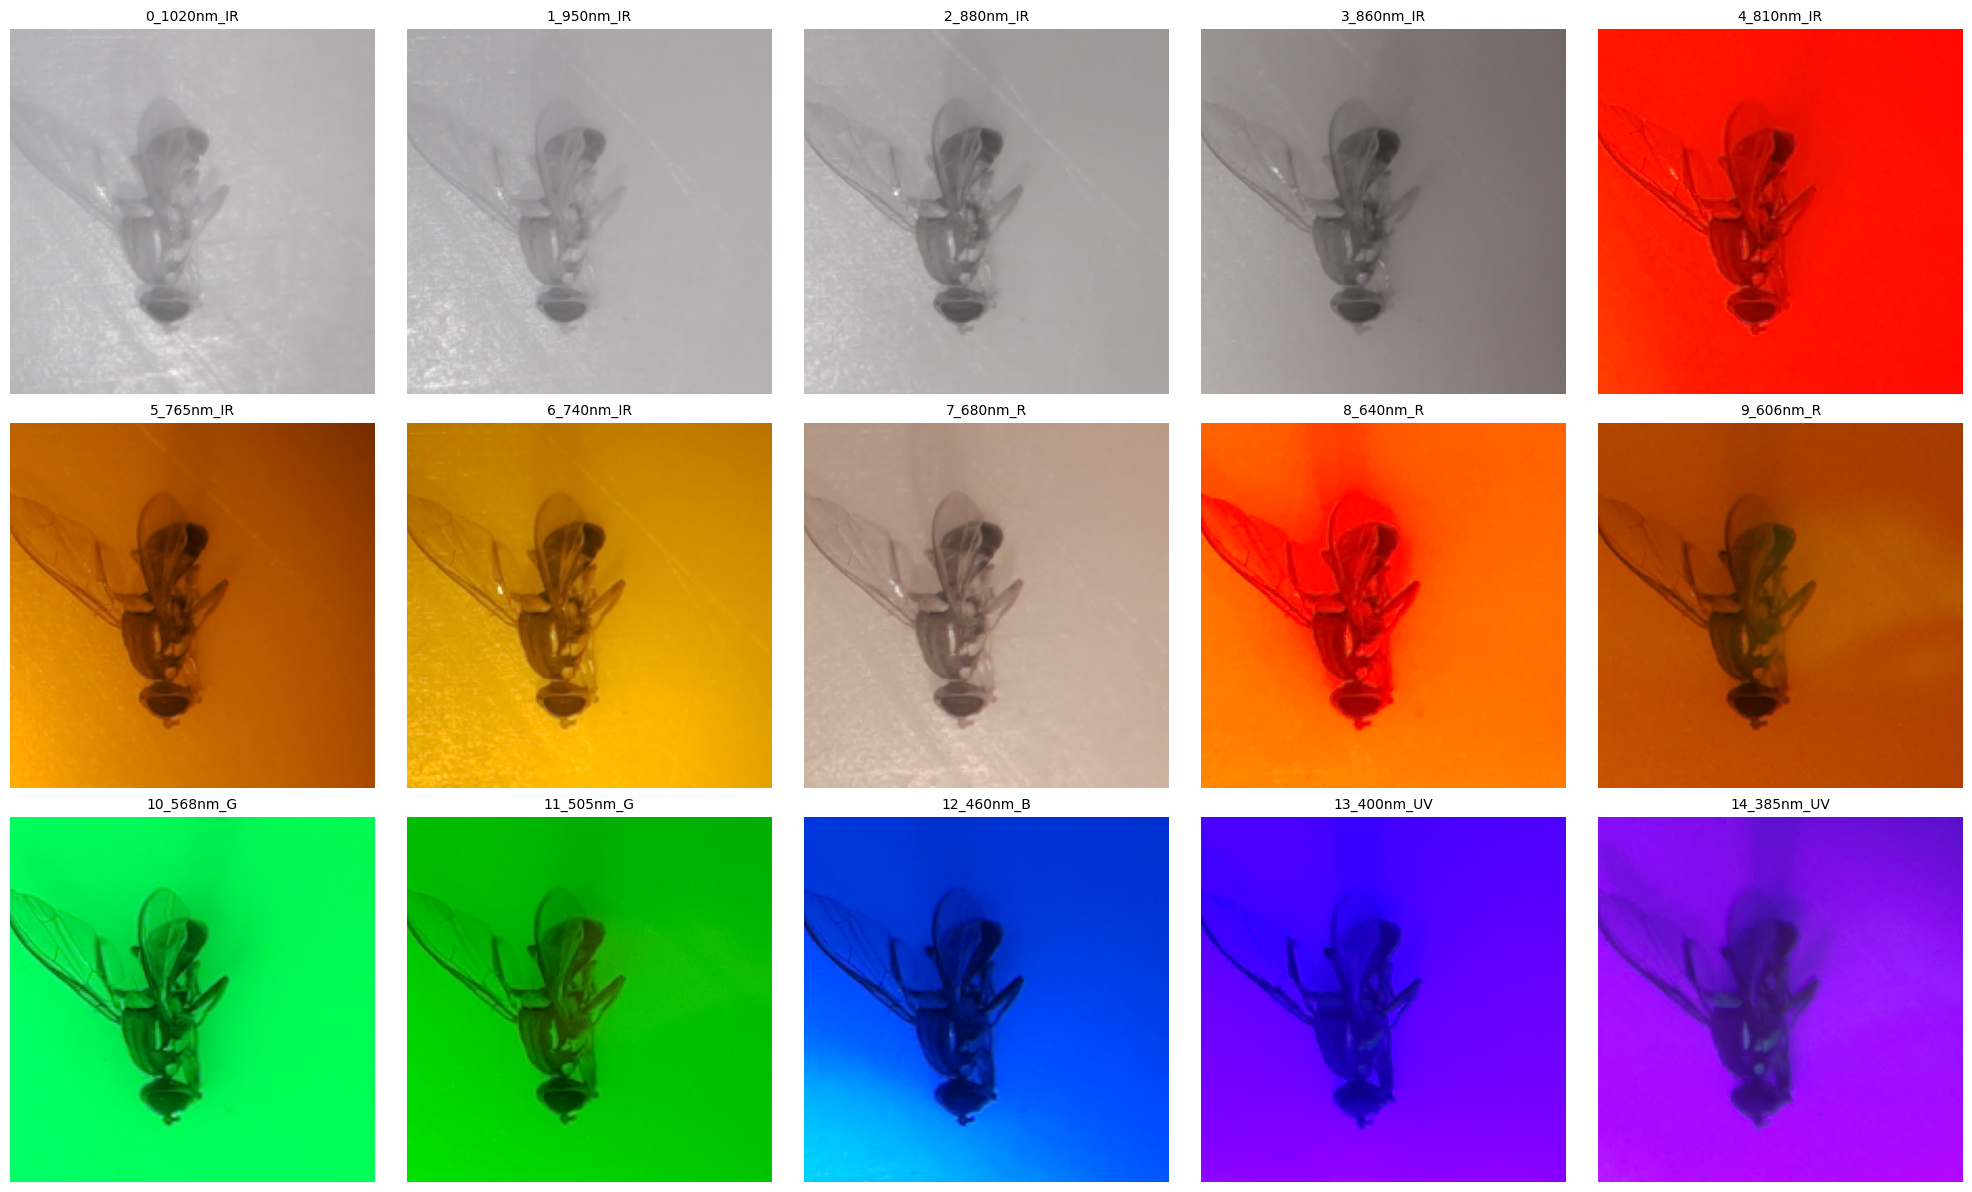

In [69]:
def static_cube_grid(filepath, collapse_method=None):
    with np.load(filepath, allow_pickle=True) as data:
        img_cube = data['data']
        bands = data['bands']
        
    fig, axes = plt.subplots(3, 5, figsize=(20, 12))
    axes = axes.flatten()
    
    for i in range(15):
        band_slice = img_cube[:, :, :, i]
        band_name = bands[i]
        
        if collapse_method is None:
            # Leave as raw RGB (BGR to RGB fix applied)
            display_img = band_slice
            cmap = None
        else:
            # Pass BOTH the image array and the band name to the custom function
            display_img = collapse_method(band_slice, band_name)
            cmap = 'gray'
            
        axes[i].imshow(display_img, cmap=cmap)
        axes[i].set_title(band_name, fontsize=10)
        axes[i].axis('off')
        
    plt.tight_layout()
    plt.show()

static_cube_grid('data/1367_b_1.npz', collapse_method=None)

# Tensorflow Loader

In [70]:
# 2. Build the multispectral tf.data pipeline
def create_tf_dataset(df, prep_method='msi', batch_size=32, img_size=(224, 224), is_training=False):
    paths = df['filepath'].values
    labels = df['label'].values
    
    # Determine output channels based on the preprocessing matrix
    if prep_method == 'rgb':
        final_channels = 3
    elif prep_method == 'monochrome':
        final_channels = 15
    else: # 'msi'
        final_channels = 45
        
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    
    def load_npz_image(path, label):
        def _load_numpy(file_path):
            with np.load(file_path.decode('utf-8'), allow_pickle=True) as data:
                img = data['data'] 
            
            h, w, colors, bands = img.shape
            
            if prep_method == 'rgb':
                # Simulating RGB camera (Band 7=R, Band 10=G, Band 12=B)
                img_final = np.stack([img[:, :, 2, 7], img[:, :, 1, 10], img[:, :, 0, 12]], axis=-1)
                
            elif prep_method == 'monochrome':
                # Sensitivity-aware collapse per band
                mono_bands = []
                for b in range(bands):
                    band_slice = img[:, :, :, b]
                    channel_intensities = np.mean(band_slice, axis=(0, 1))
                    total_intensity = np.sum(channel_intensities)
                    if total_intensity == 0:
                        weights = np.array([1/3, 1/3, 1/3])
                    else:
                        weights = channel_intensities / total_intensity
                    mono_bands.append(np.dot(band_slice, weights))
                img_final = np.stack(mono_bands, axis=-1)
                
            else:
                # Full MSI 45-channel unroll
                img_final = img.reshape(h, w, colors * bands)
                
            return img_final.astype(np.float32) / 255.0

        img = tf.numpy_function(_load_numpy, [path], tf.float32)
        img.set_shape((None, None, final_channels)) # Use None to allow original shape before resize
        img = tf.image.resize(img, img_size)
        return img, label
        
    ds = ds.map(load_npz_image, num_parallel_calls=tf.data.AUTOTUNE)
    if is_training:
        ds = ds.shuffle(buffer_size=len(df))
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

# Model Builder & Training

In [76]:
# --- 1. Custom F1 Score Metric ---
@keras.saving.register_keras_serializable()
def f1_score_metric(y_true, y_pred):
    """Custom F1-score compatible with both binary and sparse multiclass."""

    y_pred_labels = tf.round(y_pred)
    y_true_float = tf.cast(y_true, tf.float32)
    
    tp = tf.reduce_sum(y_true_float * y_pred_labels)
    fp = tf.reduce_sum((1 - y_true_float) * y_pred_labels)
    fn = tf.reduce_sum(y_true_float * (1 - y_pred_labels))
    
    epsilon = keras.backend.epsilon()
    precision = tp / (tp + fp + epsilon)
    recall = tp / (tp + fn + epsilon)
    
    return 2 * ((precision * recall) / (precision + recall + epsilon))


# --- 2. L1 Spectral Selection Layer ---
@keras.saving.register_keras_serializable()
class SpectralSelectionLayer(layers.Layer):
    def __init__(self, num_channels=45, l1_penalty=1e-3, **kwargs):
        super().__init__(**kwargs)
        self.l1_penalty = l1_penalty
        self.num_channels = num_channels

    def build(self, input_shape):
        self.channel_weights = self.add_weight(
            name='channel_weights',
            shape=(1, 1, 1, self.num_channels),
            initializer='ones',
            trainable=True,
            regularizer=keras.regularizers.L1(self.l1_penalty)
        )

    def call(self, inputs):
        return inputs * self.channel_weights
        
    def get_config(self):
        config = super().get_config()
        config.update({"num_channels": self.num_channels, "l1_penalty": self.l1_penalty})
        return config

In [77]:
# --- 3. Modular Model Builder ---
def get_model_builder(task_type, input_channels, num_classes):
    def model_builder(hp):
        model = keras.Sequential()
        model.add(layers.Input(shape=(224, 224, input_channels)))
        
        model.add(layers.RandomFlip("horizontal_and_vertical"))
        model.add(layers.RandomRotation(0.2))
        
        # Only apply L1 pruning to the full multispectral array
        if input_channels == 45:
            l1_rate = hp.Choice('l1_penalty', [1e-2, 1e-3, 1e-4])
            model.add(SpectralSelectionLayer(num_channels=45, l1_penalty=l1_rate))
        
        model.add(layers.Conv2D(
            filters=hp.Int('filters1', 32, 128, step=16),
            kernel_size=hp.Choice('kernel1', [3, 5]),
            activation='relu', padding='same'
        ))
        if hp.Choice("layer_1_pool", ["max", "avg"]) == "max":
            model.add(layers.MaxPooling2D())
        else:
            model.add(layers.AveragePooling2D(pool_size=(2, 2)))
            
        model.add(layers.Flatten())
        model.add(layers.Dense(units=hp.Int('dense_units', 64, 256, step=32), activation='relu'))
        if hp.Boolean('use_dropout'):
            model.add(layers.Dropout(hp.Float('dropout', 0.1, 0.5)))

        if task_type == 'binary':
            model.add(layers.Dense(1, activation='sigmoid'))
            loss_fn = 'binary_crossentropy'
        else:
            model.add(layers.Dense(num_classes, activation='softmax'))
            loss_fn = 'sparse_categorical_crossentropy'

        lr = hp.Float('lr', 1e-5, 1e-2, sampling='log')
        model.compile(
            optimizer=keras.optimizers.Adam(lr), 
            loss=loss_fn, 
            metrics=[f1_score_metric]
        )
        return model
    return model_builder

In [80]:
def log_experiment_results(log_file, exp_name, fold_scores, best_hps, sparsity_weights=None):
    with open(log_file, 'a', encoding='utf-8') as f:
        f.write("=" * 60 + "\n")
        f.write(f"EXPERIMENT: {exp_name}\n")
        f.write("=" * 60 + "\n")
        
        f.write("\n1. CROSS-VALIDATION METRICS\n")
        for i, score in enumerate(fold_scores):
            f.write(f"Fold {i+1} F1-Score: {score:.4f}\n")
        f.write(f"Mean F1-Score: {np.mean(fold_scores):.4f} (+/- {np.std(fold_scores):.4f})\n")
        
        f.write("\n2. OPTIMAL HYPERPARAMETERS\n")
        f.write(json.dumps(best_hps.values, indent=4) + "\n")
        
        if sparsity_weights is not None:
            f.write("\n3. L1 SPECTRAL PRUNING WEIGHTS\n")
            for i, weight in enumerate(sparsity_weights):
                status = "PRUNED" if abs(weight) < 1e-4 else f"KEPT ({weight:.4f})"
                f.write(f"Channel {i}: {status}\n")
        
        f.write("\n\n")


def generate_model_report(tuner, final_model, history, test_dataset, input_channels):
    print("-" * 50)
    print("OPTIMAL HYPERPARAMETERS")
    print("-" * 50)
    best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
    print(json.dumps(best_hps.values, indent=4))
    
    if input_channels == 45:
        print("\n" + "-" * 50)
        print("L1 SPECTRAL PRUNING WEIGHTS")
        print("-" * 50)
        sparsity_weights = final_model.get_layer('spectral_selection_layer').get_weights()[0].flatten()
        for i, weight in enumerate(sparsity_weights):
            status = "PRUNED" if abs(weight) < 1e-4 else f"KEPT ({weight:.4f})"
            print(f"Channel {i}: {status}")

    print("\n" + "-" * 50)
    print("TEST SET EVALUATION")
    print("-" * 50)
    test_results = final_model.evaluate(test_dataset, verbose=0)
    print(f"Test Loss: {test_results[0]:.4f}")
    print(f"Test F1-Score: {test_results[1]:.4f}")
    
    # Plotting
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    ax1.plot(history.history['loss'], label='Train Loss')
    ax1.plot(history.history['val_loss'], label='Validation Loss')
    ax1.set_title('Model Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    
    ax2.plot(history.history['f1_score_metric'], label='Train F1')
    ax2.plot(history.history['val_f1_score_metric'], label='Validation F1')
    ax2.set_title('Model F1-Score')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('F1-Score')
    ax2.legend()
    
    plt.tight_layout()
    plt.show()

In [ ]:
# --- 1. Define the Experimental Matrix ---
TASK_TYPES = [
    'binary', 
    # 'multi'  # Temporarily disabled
]
PREPROCESSING_METHODS = ['rgb', 'msi', 'monochrome']
NUM_FOLDS = 5

for task in TASK_TYPES:
    for prep in PREPROCESSING_METHODS:
        exp_name = f"{task}_{prep}_experiment"
        print("=" * 60)
        print(f"STARTING EXPERIMENT: {exp_name}")
        print("=" * 60)
        
        # 1. Load the full base DataFrame
        df, num_classes = load_npz_dataframe(task_type=task) 
        
        # Split a small holdout set for the tuner (20% of total data), keep the rest (80%) for CV
        # Note: test_size=0.8 means 80% goes to cv_df, 20% to tune_df
        tune_df, cv_df = train_test_split(df, test_size=0.8, stratify=df['label'], random_state=RANDOM_STATE)
        
        # Split the tuner data into train and validation (80/20 split of the tune_df)
        tune_train, tune_val = train_test_split(tune_df, test_size=0.2, stratify=tune_df['label'], random_state=RANDOM_STATE)
        
        # Build TF datasets for Tuning
        tune_train_ds = create_tf_dataset(tune_train, prep_method=prep, is_training=True)
        tune_val_ds = create_tf_dataset(tune_val, prep_method=prep)
        
        input_channels = 3 if prep == 'rgb' else (15 if prep == 'monochrome' else 45)
        
        # 2. Hyperparameter Tuning (The Model Matrix)
        tuner = kt.Hyperband(
            get_model_builder(task, input_channels, num_classes),
            objective=kt.Objective('val_f1_score_metric', direction='max'),
            max_epochs=20,
            factor=3,
            directory='training_logs',
            project_name=f"tune_{exp_name}"
        )
        
        early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)
        
        # Execute the search
        tuner.search(tune_train_ds, validation_data=tune_val_ds, epochs=20, callbacks=[early_stop], verbose=1)
        best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
        
        # 3. K-Fold Cross Validation
        print(f"\nStarting {NUM_FOLDS}-Fold Cross Validation for best architecture...")
        skf = StratifiedKFold(n_splits=NUM_FOLDS, shuffle=True, random_state=RANDOM_STATE)
        
        fold_f1_scores = []
        
        # Generate split indices based on the CV dataframe
        for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(cv_df)), cv_df['label'])):
            print(f"--- Training Fold {fold + 1}/{NUM_FOLDS} ---")
            
            fold_train_df = cv_df.iloc[train_idx]
            fold_val_df = cv_df.iloc[val_idx]
            
            fold_train_ds = create_tf_dataset(fold_train_df, prep_method=prep, is_training=True)
            fold_val_ds = create_tf_dataset(fold_val_df, prep_method=prep)
            
            # Build fresh optimal model for this fold
            model = tuner.hypermodel.build(best_hps)
            checkpoint_path = f"checkpoints/{exp_name}_fold{fold+1}.keras"
            
            checkpoint_cb = keras.callbacks.ModelCheckpoint(
                filepath=checkpoint_path,
                save_best_only=True,
                monitor='val_f1_score_metric',
                mode='max'
            )
            
            model.fit(
                fold_train_ds, 
                validation_data=fold_val_ds, 
                epochs=40, 
                callbacks=[early_stop, checkpoint_cb], 
                verbose=0
            )
            
            # Load the best checkpointed weights to evaluate
            model.load_weights(checkpoint_path)
            results = model.evaluate(fold_val_ds, verbose=0)
            
            # metric index 1 is the custom f1_score_metric
            fold_f1 = results[1] 
            fold_f1_scores.append(fold_f1)
            print(f"Fold {fold + 1} F1-Score: {fold_f1:.4f}")
            
        print(f"\n*** {exp_name} CV F1-Score: {np.mean(fold_f1_scores):.4f} (+/- {np.std(fold_f1_scores):.4f}) ***\n")

        # Extract L1 weights only if using the full 45-channel array
        final_sparsity_weights = None
        if prep == 'msi':
            # Load the best checkpointed weights to extract sparsity weights
            model.load_weights(checkpoint_path)
            final_sparsity_weights = model.get_layer('spectral_selection_layer').get_weights()[0].flatten()
            
        # Append results to the master log
        log_experiment_results(
            log_file="ablation_study_results.txt",
            exp_name=exp_name,
            fold_scores=fold_f1_scores,
            best_hps=best_hps,
            sparsity_weights=final_sparsity_weights
        )

Trial 30 Complete [00h 04m 01s]
val_accuracy: 0.7307692170143127

Best val_accuracy So Far: 0.8846153616905212
Total elapsed time: 02h 15m 08s
